# 01. The engine and its validation

## 1. Objective
Price European, Asian, barrier and American options by Monte Carlo and check every price against an independent benchmark.

## 2. Inputs and the step rule
252 trading days; expiry < 30 days -> 0.5-day steps, otherwise 1-day steps.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)

In [2]:
from src.pricer import price_option
from src.paths import step_rule
for d in (10, 29, 30, 90): print(d, 'days ->', step_rule(d)[0], 'steps of', step_rule(d)[2], 'day')

10 days -> 20 steps of 0.5 day
29 days -> 58 steps of 0.5 day
30 days -> 30 steps of 1.0 day
90 days -> 90 steps of 1.0 day


## 3. One price of each style (100k paths, fixed seed)

In [3]:
S0, K, r, sig = 100, 100, 0.05, 0.2
print(price_option(S0, K, 90, r, sig, 'call', 'european', 100_000, seed=1))
print(price_option(S0, K, 90, r, sig, 'call', 'asian', 100_000, seed=1, variance_reduction='control'))
print(price_option(S0, K, 90, r, sig, 'call', 'barrier', 100_000, 115, 'up-and-out', seed=1))
print(price_option(S0, K, 90, r, sig, 'put', 'american', 50_000, seed=1))

PricingResult(price=5.7069, se=0.0256, 95%CI=[5.6568, 5.7571], european, steps=90 x 1.0d, 0.78s)


PricingResult(price=3.2107, se=0.0002, 95%CI=[3.2103, 3.2111], asian, steps=90 x 1.0d, 0.29s)


PricingResult(price=1.6551, se=0.0102, 95%CI=[1.6352, 1.6751], barrier, steps=90 x 1.0d, 0.26s)


PricingResult(price=4.0080, se=0.0219, 95%CI=[3.9651, 4.0508], american, steps=90 x 1.0d, 1.07s)


Each result has the price, the **standard error**, a 95% confidence interval, the step size and the runtime.

## 4. European vs Black-Scholes
30 cases (expiry 10-252 days, three strikes, calls and puts).

In [4]:
v = pd.read_csv('../outputs/tables/01_european_validation.csv'); print('inside 95% CI:', v.inside_ci.mean().round(3), ' max |z|:', v.z.abs().max().round(2), ' max abs error: $', v.error.abs().max().round(4)); v.head(8).round(4)

inside 95% CI: 0.933  max |z|: 2.2  max abs error: $ 0.0492


,expiry_days,K,type,steps,step_days,mc,se,bs,error,z,inside_ci
0,10,90,call,20,0.5,10.1829,0.0005,10.1825,0.0004,0.8157,True
1,10,90,put,20,0.5,0.0042,0.0002,0.0041,0.0001,0.3631,True
2,10,100,call,20,0.5,1.6928,0.0040,1.6888,0.0040,0.9972,True
3,10,100,put,20,0.5,1.4942,0.0036,1.4906,0.0036,0.9931,True
4,10,110,call,20,0.5,0.0141,0.0004,0.0135,0.0006,1.2992,True
5,10,110,put,20,0.5,9.7956,0.0004,9.7954,0.0001,0.2932,True
6,29,90,call,58,0.5,10.6509,0.0026,10.6527,-0.0018,-0.6938,True
7,29,90,put,58,0.5,0.1353,0.0017,0.1363,-0.0011,-0.6366,True


z calibration over 300 seeds: {'mean': -0.04552672077129828, 'sd': 1.004462203783406, 'frac_outside_196': 0.04666666666666667}


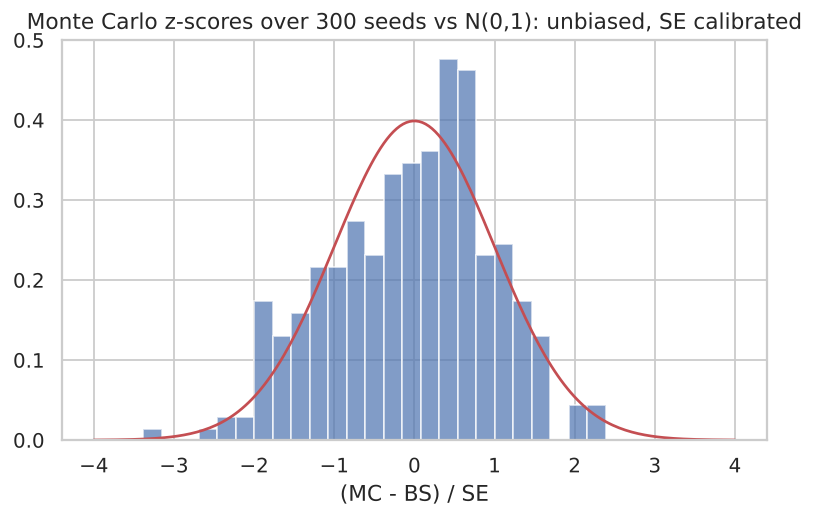

In [5]:
import json; s = json.load(open('../outputs/summary.json')); print('z calibration over 300 seeds:', s['z_calibration'])
display(Image('../outputs/figures/01_z_score_calibration.png'))

The z-scores (MC minus Black-Scholes divided by the standard error) look like a standard normal: the engine is **unbiased** and its **standard error is correct**.

## 5. Convergence and variance reduction

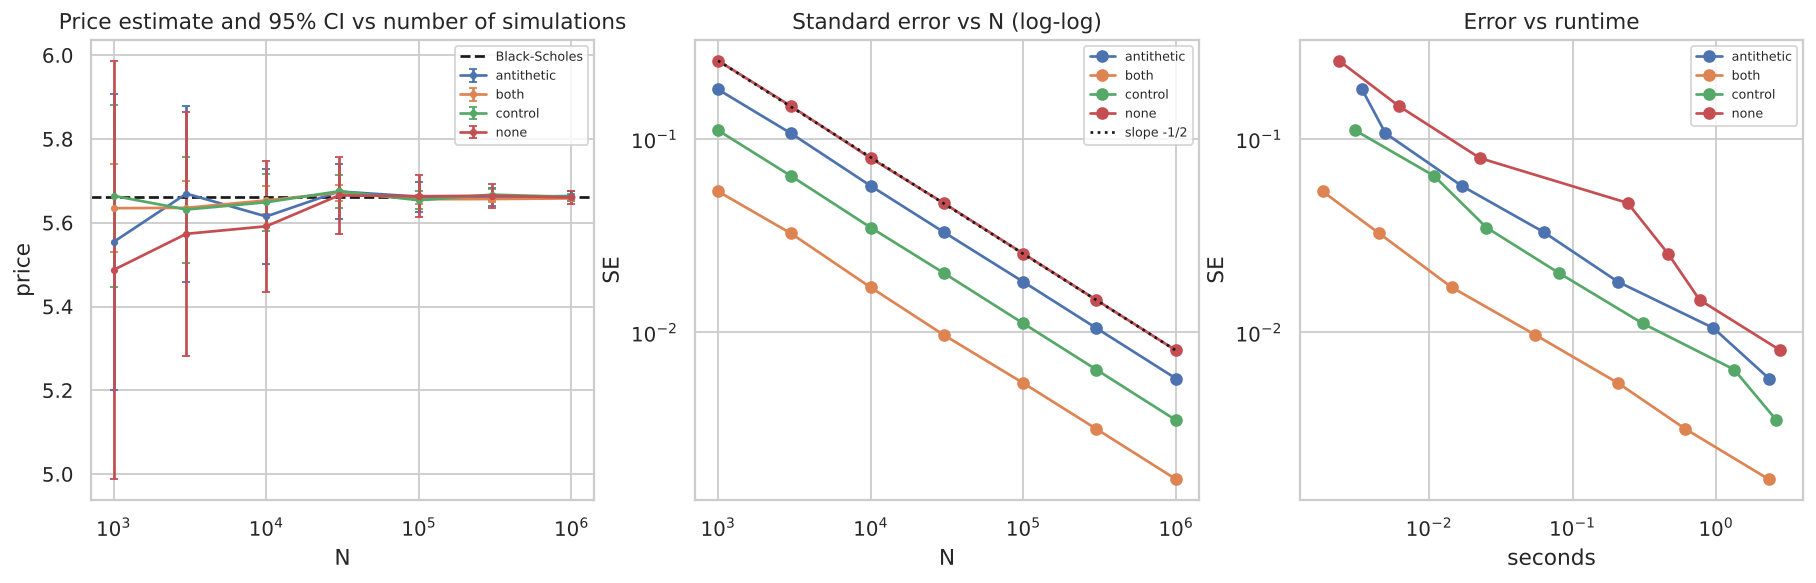

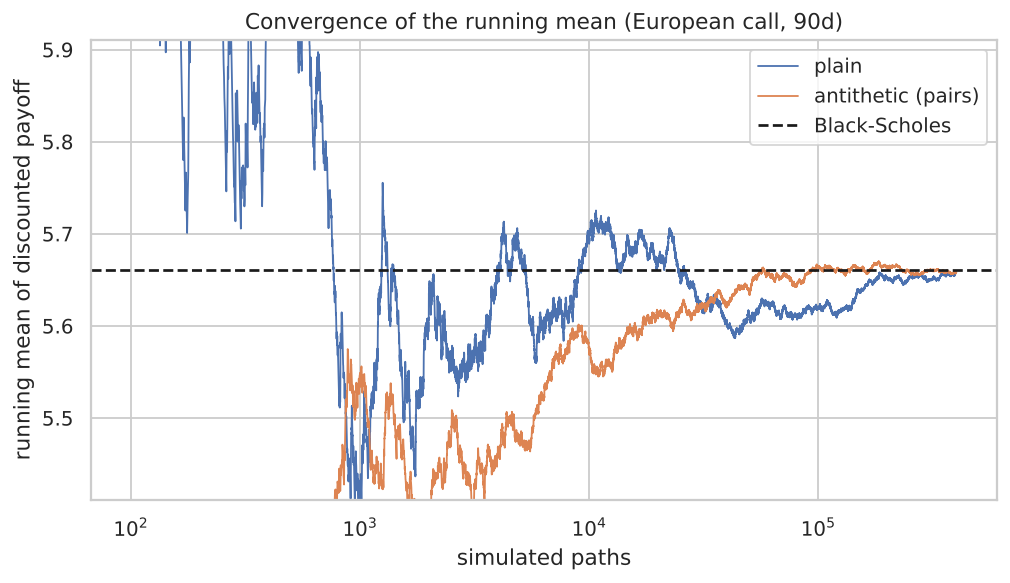

log-log slope of SE vs N: -0.4999


In [6]:
display(Image('../outputs/figures/02_convergence_and_variance_reduction.png')); display(Image('../outputs/figures/03_running_mean_convergence.png'))
print('log-log slope of SE vs N:', round(s['se_loglog_slope_plain'], 4))

In [7]:
pd.read_csv('../outputs/tables/03_variance_reduction_efficiency.csv').round(4)

,case,method,price,se,runtime_s,efficiency_vs_plain,se_reduction_x
0,european call,none,5.6670,0.0255,0.6163,1.0000,1.0000
1,european call,antithetic,5.6335,0.0182,0.2033,5.9655,1.4029
2,european call,control,5.6524,0.0111,0.2499,13.1109,2.3057
3,european call,both,5.6540,0.0055,0.2082,63.5797,4.6350
4,asian call (arithmetic),none,3.2282,0.0144,0.2631,1.0000,1.0000
5,asian call (arithmetic),antithetic,3.2059,0.0101,0.2184,2.4298,1.4203
6,asian call (arithmetic),control,3.2112,0.0002,0.2962,3471.2996,62.5195
7,asian call (arithmetic),both,3.2111,0.0002,0.2421,3997.5216,60.6582
8,up-and-out call (H=115),none,1.6348,0.0102,0.4878,1.0000,1.0000
9,up-and-out call (H=115),antithetic,1.6377,0.0088,0.2367,2.7724,1.1599


* The slope -0.5 is the central limit theorem.
* Antithetic variates cut the European SE by 1.4x, a control variate by 2.3x, both by 4.6x.
* The geometric-average control variate for the arithmetic Asian is extremely effective (62x): the two payoffs are almost perfectly correlated.
* Barrier payoffs gain little from antithetics because the knock-out indicator is not monotonic.

## 6. Paths and payoff distributions

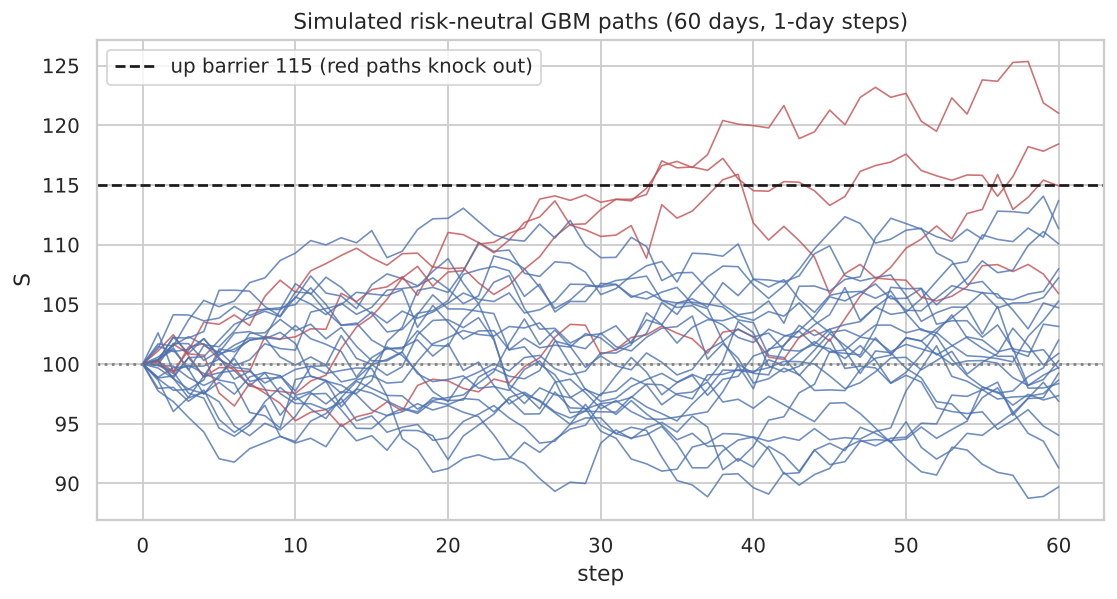

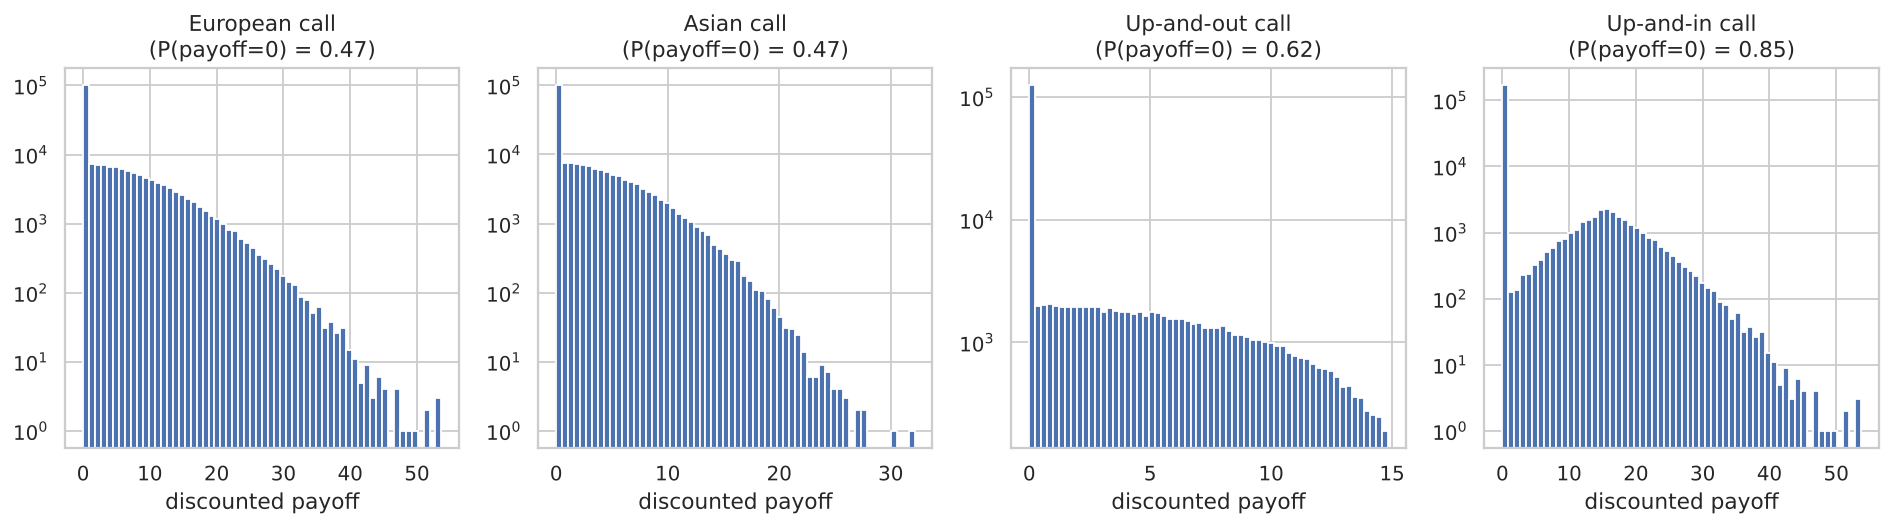

{'European call': 0.47114, 'Asian call': 0.46991, 'Up-and-out call': 0.618135, 'Up-and-in call': 0.853005}


In [8]:
display(Image('../outputs/figures/12_sample_paths.png')); display(Image('../outputs/figures/13_payoff_distributions.png')); print(s['p_zero_payoff'])

Call payoffs are zero in about half the paths; knock-in options are worthless in 85% of paths: their value is concentrated in rare events, so their Monte Carlo error is relatively large.

## 7. Conclusion
The engine reproduces closed forms within statistical error and has a calibrated standard error.